In [1]:
import numpy as np
import matplotlib.pyplot as plt
from hyperillumination_utils import *
from astro_utils import *
from HItargets_utils import *
from paper_plot_utils import paper_figure, paper_theme
import os, contextlib, io
from dataclasses import replace
with contextlib.redirect_stdout(io.StringIO()):   # mute "no spidermanrc file detected"
    from simple_bias_analysis import overlay_planets

# Exoplanet Archive (to overlay known rocky planets on the a/Rs - Rp/Rs maps)
AGG = os.path.join(os.path.dirname(os.path.abspath('')), 'NASAExoplanetArchive', 'NASAExoArchive_2026-08-21_aggregate_short.csv')

In [2]:
# Target planet: from the NASA Exoplanet Archive, or a CUSTOM entry in HItargets_utils (K2-141 b: Malavolta et al. 2018, Barragán et al. 2018)
planet = hi_planets_by_name("TOI 2431 b") # "K2-141 b", "TOI-2431 b"

u, u_B = DEFAULT_U, DEFAULT_U_B   # transit and irradiance limb darkening (baseline settings, HItargets_utils.py)
A_B = DEFAULT_A_B   # Bond albedo: sets the temperature map

In [3]:
# Basic Hyperillumination Stats
planet.summary(print_params=True, eff_wavelength_range=filter_lambda("MIRI/LRS"))

=== TOI-2431 b ===
    name = TOI-2431 b
  period = 0.22419578
    incl = 74.0
     ecc = 0.0
       w = 90.0
      r1 = 0.02131
      r2 = 1.0
       R = 2.080956345198848
  T2_eff = 4109.0
    a_AU = 0.0063
     T14 = 0.7475
    logg = 4.68
     feh = -0.02
--- derived ---
rp = r1/r2           = 0.0213
a  = R/r2            = 2.081
terminator_penumbra  = 60.6 deg
terminator_nightside = 118.1 deg
fraction_illuminated = 73.5 %  (fully illuminated: 25.5 %, penumbra: 48.1 %)
substellar_boost     = 2.07999 % (insolation), 0.51599 % (temperature)
approx_occ_depth     = 219.2 ppm


### Comparison Nguyen et al. (2020)

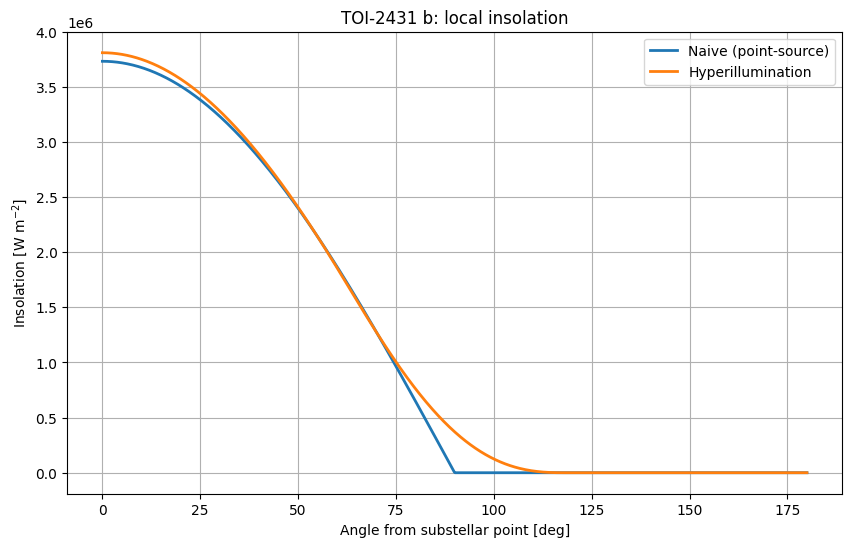

In [4]:
PAPER_MODE = False
gamma1_deg = np.linspace(0, 180, 1000)  # angle from substellar point [deg]
insol_naive = naive_insolation(np.radians(gamma1_deg), planet)
insol_hyperillum = insolation_hyperillum(np.radians(gamma1_deg), planet, u_B=u_B)

plt.figure(figsize=(10, 6))
plt.plot(gamma1_deg, insol_naive, linewidth=2, label="Naive (point-source)")
plt.plot(gamma1_deg, insol_hyperillum, linewidth=2, label="Hyperillumination")

plt.xlabel("Angle from substellar point [deg]")
plt.ylabel(r"Insolation [W m$^{-2}$]")
plt.title(f"{planet.name}: local insolation")
plt.legend()
plt.grid()
paper_figure(f"insol_profile_{planet.name.replace(' ', '')}", PAPER_MODE)
plt.show()

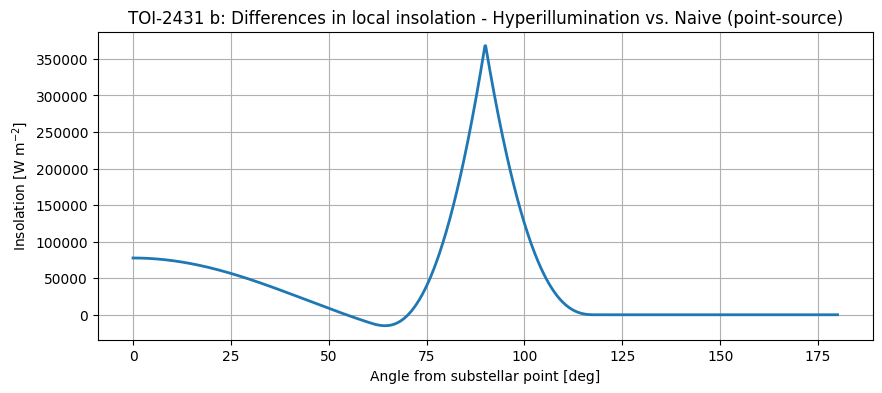

In [5]:
PAPER_MODE = False
plt.figure(figsize=(10, 4))
plt.plot(gamma1_deg, insol_hyperillum-insol_naive, linewidth=2)
plt.xlabel("Angle from substellar point [deg]")
plt.ylabel(r"Insolation [W m$^{-2}$]")
plt.title(f"{planet.name}: Differences in local insolation - Hyperillumination vs. Naive (point-source)")
plt.grid()
paper_figure(f"insol_profile_diff_{planet.name.replace(' ', '')}", PAPER_MODE)
plt.show()

Luger 2022 & Carter 2024 predict that hyper-illumination models predict a hotter substellar point than the plane-parallel approximation.

paper figure saved: paper_figures/TempCurve.pdf


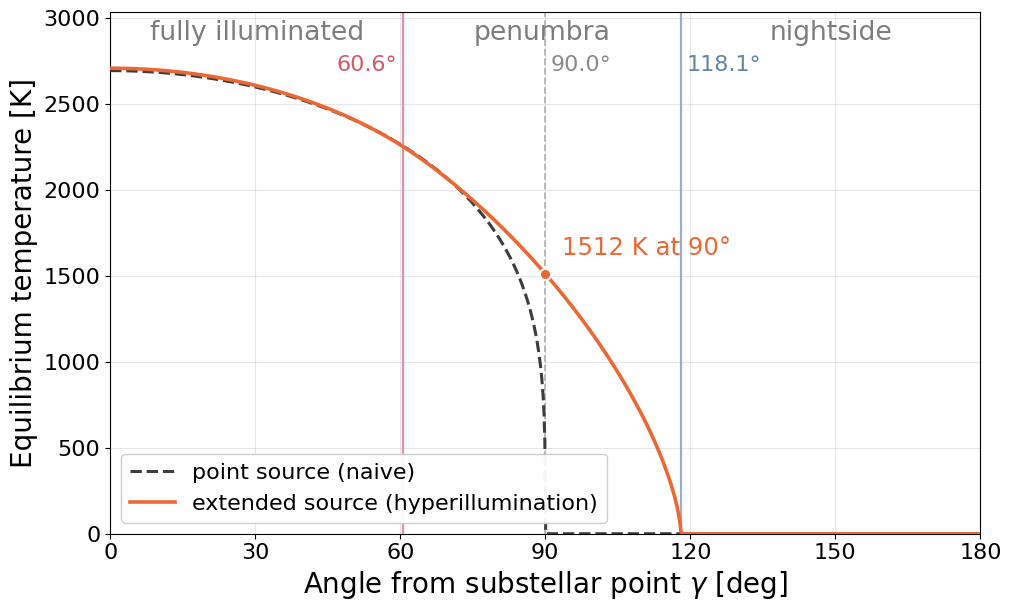

Hyperillumination temperature at 90 deg: 1512 K -> local blackbody spectrum peaks at 1.92 um  (TOI-2431 b, A_B = 0.20, u_B = 0.50)


In [6]:
PAPER_MODE = True
temp_naive = BBtemp_from_insolation(insol_naive, A_B=A_B)
temp_hyperillum = BBtemp_from_insolation(insol_hyperillum, A_B=A_B)

# zone borders (PlanetParams): end of the fully illuminated zone gamma_f and the terminator gamma_t; colours as in the illumination-zone plot below
gamma_f_p, gamma_t_p = planet.terminator_penumbra(unit="deg"), planet.terminator_nightside(unit="deg")
c_fi, c_pen, c_night = "#f4d35e", "#ee964b", "#8d99ae"
c_hi, c_naive = "#0f766e", "#3d3d3d"   # teal: stands apart from the zone shading and the red / blue border lines
# paper version: hyperillumination in the orange of the other paper figures, no zone shading, fainter zone borders, neutral zone names
if PAPER_MODE: c_hi = "#eb6834"
border_alpha = 0.45 if PAPER_MODE else 1.
c_zone_names = ("0.4",) * 3 if PAPER_MODE else ("#9c7a00", "#b4541a", "#4f5d75")
T_90 = float(np.interp(90., gamma1_deg, temp_hyperillum))
T_top = 1.12 * max(temp_hyperillum.max(), temp_naive.max())

fig, ax = plt.subplots(figsize=(10, 6))
if not PAPER_MODE:
    for lo, hi, col in ((0., gamma_f_p, c_fi), (gamma_f_p, gamma_t_p, c_pen), (gamma_t_p, 180., c_night)):
        ax.axvspan(lo, hi, color=col, alpha=0.25, lw=0, zorder=0)
ax.axvline(gamma_f_p, color="#c1121f", lw=1.6, alpha=border_alpha, zorder=1)
ax.axvline(gamma_t_p, color="#1d4e89", lw=1.6, alpha=border_alpha, zorder=1)
ax.axvline(90., color="0.35", ls="--", lw=1.3, alpha=border_alpha, zorder=1)

ax.plot(gamma1_deg, temp_naive, color=c_naive, ls="--", lw=2.2, zorder=3, label="point source (naive)")
ax.plot(gamma1_deg, temp_hyperillum, color=c_hi, lw=2.6, zorder=4, label="extended source (hyperillumination)")

# the point-source terminator is still hot under hyperillumination
ax.plot(90., T_90, "o", color=c_hi, ms=8, mec="white", mew=1.4, zorder=5)
ax.annotate(f"{T_90:.0f} K at 90°", (90., T_90), xytext=(12, 10), textcoords="offset points", ha="left", va="bottom", fontsize=11, color=c_hi, zorder=6)

# zone names along the top, and the border angles just below them
label_kw = dict(ha="center", va="top", fontsize=12, alpha=0.85, zorder=6)
for x_, name_, col_ in zip((gamma_f_p / 2., (gamma_f_p + gamma_t_p) / 2., (gamma_t_p + 180.) / 2.), ("fully illuminated", "penumbra", "nightside"), c_zone_names):
    ax.text(x_, 0.985 * T_top, name_, color=col_, **label_kw)
for gam, col, ha, dx in ((gamma_f_p, "#c1121f", "right", -4), (gamma_t_p, "#1d4e89", "left", 4), (90., "0.35", "left", 4)):
    ax.annotate(f"{gam:.1f}°", (gam, 0.90 * T_top), xytext=(dx, 0), textcoords="offset points", ha=ha, va="center", fontsize=10, color=col, alpha=max(border_alpha, 0.7), zorder=6)

ax.set(xlim=(0., 180.), ylim=(0., T_top), xlabel=r"Angle from substellar point $\gamma$ [deg]", ylabel="Equilibrium temperature [K]",
       title=f"{planet.name}: local blackbody temperature ($A_B$ = {A_B:.2f}, $u_B$ = {u_B:.2f})")
ax.set_xticks(np.arange(0, 181, 30))
ax.grid(alpha=0.3, zorder=0)
ax.legend(loc="lower left", framealpha=0.95)   # the lower left of the fully illuminated zone is always empty (the curves stay hot there)
paper_figure(f"TempCurve", PAPER_MODE, fig=fig, label_size=20)   # axis labels stand out from the 16 pt tick labels
plt.show()

print(f"Hyperillumination temperature at 90 deg: {T_90:.0f} K -> local blackbody spectrum peaks at {1e6 * wien_lambda_max(T_90):.2f} um  ({planet.name}, A_B = {A_B:.2f}, u_B = {u_B:.2f})")


The terminator of the point-source model (90°) is still hot under hyperillumination, so the local blackbody spectrum there peaks in the near-infrared, far short of the MIRI range (4.9 to 28.8 µm); the cell above prints the temperature and the Wien peak for the current $A_B$ and $u_B$.

insolation_penumbra_mask runtime: 5.3078 s
insolation_penumbra_hyperillum runtime: 0.0027 s
insolation_penumbra_hyperillum_simpleint runtime: 7.3914 s
insolation_penumbra_hyperillum_approx runtime: 0.0001 s


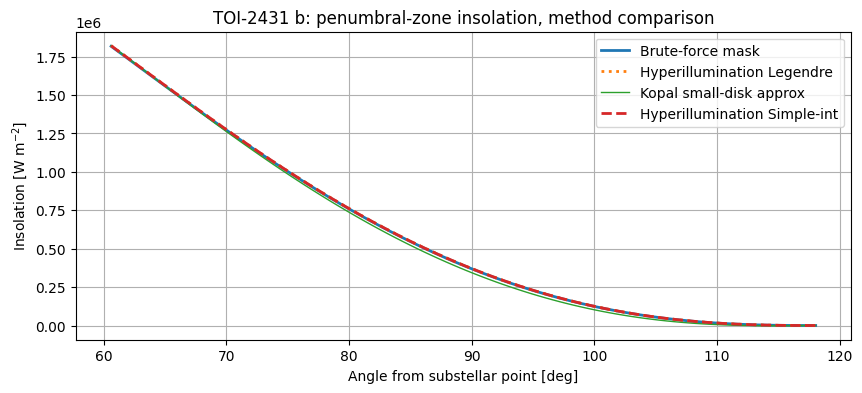

In [7]:
PAPER_MODE = False
gamma1_pen_deg = np.linspace(planet.terminator_penumbra(unit="deg"), planet.terminator_nightside(unit="deg"), 100)

insol_mask = insolation_penumbra_mask(np.radians(gamma1_pen_deg), planet, runtime=True, u_B=u_B)
insol_hyperillum_legendre = insolation_penumbra_hyperillum(np.radians(gamma1_pen_deg), planet, runtime=True, u_B=u_B)
insol_hyperillum_simpleint = insolation_penumbra_hyperillum_simpleint(np.radians(gamma1_pen_deg), planet, runtime=True, u_B=u_B)
insol_hyperillum_approx = insolation_penumbra_hyperillum_approx(np.radians(gamma1_pen_deg), planet, runtime=True, u_B=u_B)

plt.figure(figsize=(10, 4))
plt.plot(gamma1_pen_deg, insol_mask, linewidth=2, label="Brute-force mask")
plt.plot(gamma1_pen_deg, insol_hyperillum_legendre, linewidth=2, linestyle=":", label="Hyperillumination Legendre")
plt.plot(gamma1_pen_deg, insol_hyperillum_approx, linewidth=1, label="Kopal small-disk approx")
plt.plot(gamma1_pen_deg, insol_hyperillum_simpleint, linewidth=2, linestyle="--", label="Hyperillumination Simple-int")


plt.xlabel("Angle from substellar point [deg]")
plt.ylabel(r"Insolation [W m$^{-2}$]")
plt.title(f"{planet.name}: penumbral-zone insolation, method comparison")
plt.legend()
plt.grid()
paper_figure(f"penumbra_insol_methods_{planet.name.replace(' ', '')}", PAPER_MODE)
plt.show()

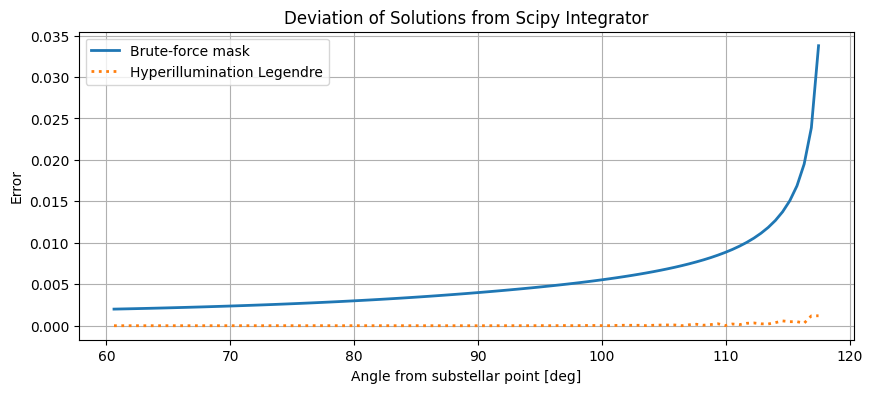

In [8]:
PAPER_MODE = False
plt.figure(figsize=(10, 4))
plt.plot(gamma1_pen_deg, np.abs(1-insol_mask/insol_hyperillum_simpleint), linewidth=2, label="Brute-force mask")
plt.plot(gamma1_pen_deg, np.abs(1-insol_hyperillum_legendre/insol_hyperillum_simpleint), linewidth=2, linestyle=":", label="Hyperillumination Legendre")
#plt.plot(gamma1_pen_deg, np.abs(1-insol_hyperillum_approx/insol_hyperillum_simpleint), linewidth=1, label="Kopal small-disk approx")

plt.xlabel("Angle from substellar point [deg]")
plt.ylabel("Error")
plt.title("Deviation of Solutions from Scipy Integrator")
plt.legend()
plt.grid()
paper_figure(f"penumbra_insol_methods_error_{planet.name.replace(' ', '')}", PAPER_MODE)
plt.show()

TOI-2431 b: gamma_f = 60.61 deg, gamma_t = 118.05 deg
ours vs Kang (u_B = 0):        max |dI|/I_sub = 1.6e-06,  max rel. error where I > 1% I_sub = 1.2e-04
ours vs brute force (u_B = 0.0): max |dI|/I_sub = 1.3e-06
ours vs brute force (u_B = 0.5): max |dI|/I_sub = 1.4e-06


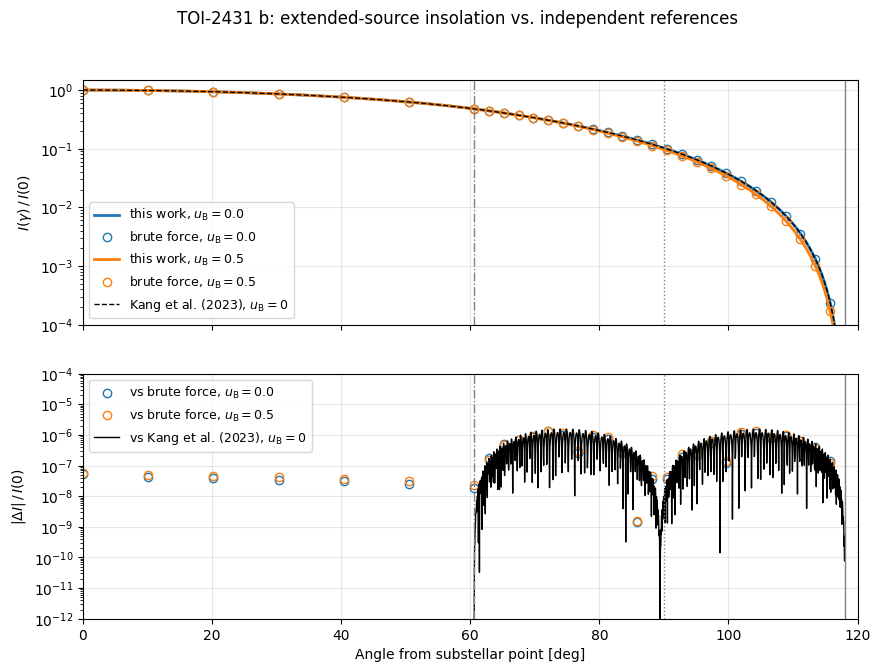

In [9]:
PAPER_MODE = False
# Validation of insolation_hyperillum against two references that share no formula with it:
#   insolation_kang:                  closed form of Kang, Nimmo & Ding (2023), exact for a uniformly bright disk (u_B = 0); cheap -> dense grid
#   insolation_hyperillum_bruteforce: vector integration over the stellar sphere, any u_B; ~1 s per point -> coarse grid, parallel over points
from joblib import Parallel, delayed
from joblib.externals.loky import get_reusable_executor

gf_deg, gt_deg = planet.terminator_penumbra(unit="deg"), planet.terminator_nightside(unit="deg")
gamma_dense_deg = np.linspace(0., gt_deg, 3000, endpoint=False)
gamma_bf_deg = np.concatenate([np.linspace(0., gf_deg, 6, endpoint=False), np.linspace(gf_deg, gt_deg, 25, endpoint=False)])
u_B_values = (0., u_B)
I_sub = insolation_hyperillum(0., planet)[0]   # substellar insolation (independent of u_B)

insol_kang = insolation_kang(np.radians(gamma_dense_deg), planet)
insol_ours_dense = {u: insolation_hyperillum(np.radians(gamma_dense_deg), planet, u_B=u) for u in u_B_values}
insol_ours_bf = {u: insolation_hyperillum(np.radians(gamma_bf_deg), planet, u_B=u) for u in u_B_values}
insol_bf = {u: np.concatenate(Parallel(n_jobs=-1, backend="loky")(
                delayed(insolation_hyperillum_bruteforce)(np.radians([g]), planet, u_B=u) for g in gamma_bf_deg))
            for u in u_B_values}
get_reusable_executor().shutdown(wait=True)

# errors in units of the substellar insolation; relative errors only where the insolation exceeds 1 % of it
err_kang = np.abs(insol_ours_dense[0.] - insol_kang) / I_sub
bright = insol_kang > 1e-2 * I_sub
print(f"{planet.name}: gamma_f = {gf_deg:.2f} deg, gamma_t = {gt_deg:.2f} deg")
print(f"ours vs Kang (u_B = 0):        max |dI|/I_sub = {err_kang.max():.1e},  max rel. error where I > 1% I_sub = {np.max(np.abs(insol_ours_dense[0.][bright] / insol_kang[bright] - 1)):.1e}")
for u in u_B_values:
    print(f"ours vs brute force (u_B = {u}): max |dI|/I_sub = {np.max(np.abs(insol_ours_bf[u] - insol_bf[u])) / I_sub:.1e}")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
colors = {0.: "C0", u_B: "C1"}
for u in u_B_values:
    ax1.plot(gamma_dense_deg, insol_ours_dense[u] / I_sub, color=colors[u], linewidth=2, label=fr"this work, $u_{{\rm B}} = {u}$")
    ax1.plot(gamma_bf_deg, insol_bf[u] / I_sub, "o", color=colors[u], markerfacecolor="none", label=fr"brute force, $u_{{\rm B}} = {u}$")
    ax2.plot(gamma_bf_deg, np.abs(insol_ours_bf[u] - insol_bf[u]) / I_sub, "o", color=colors[u], markerfacecolor="none", label=fr"vs brute force, $u_{{\rm B}} = {u}$")
ax1.plot(gamma_dense_deg, insol_kang / I_sub, color="k", linestyle="--", linewidth=1, label=r"Kang et al. (2023), $u_{\rm B} = 0$")
ax2.plot(gamma_dense_deg, err_kang, color="k", linewidth=1, label=r"vs Kang et al. (2023), $u_{\rm B} = 0$")

for ax in (ax1, ax2):
    for g, ls in ((gf_deg, "-."), (90., ":"), (gt_deg, "-")):
        ax.axvline(g, color="gray", linestyle=ls, linewidth=1)
    ax.set_yscale("log")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=9)
ax1.set_ylim(1e-4, 1.5)
ax1.set_ylabel(r"$I(\gamma)\,/\,I(0)$")
ax2.set_ylim(1e-12, 1e-4)
ax2.set_ylabel(r"$|\Delta I|\,/\,I(0)$")
ax2.set_xlabel("Angle from substellar point [deg]")
ax2.set_xlim(0, gt_deg + 2)
fig.suptitle(f"{planet.name}: extended-source insolation vs. independent references")
paper_figure(f"insol_validation_{planet.name.replace(' ', '')}", PAPER_MODE)
plt.show()

### Illuminated Fractions of Exoplanet

In [10]:
planet.fraction_illuminated("extra")

{'fully illuminated': np.float64(0.25460561622151484),
 'penumbra': np.float64(0.48054828363275626)}

paper figure saved: paper_figures/hi_zones.pdf


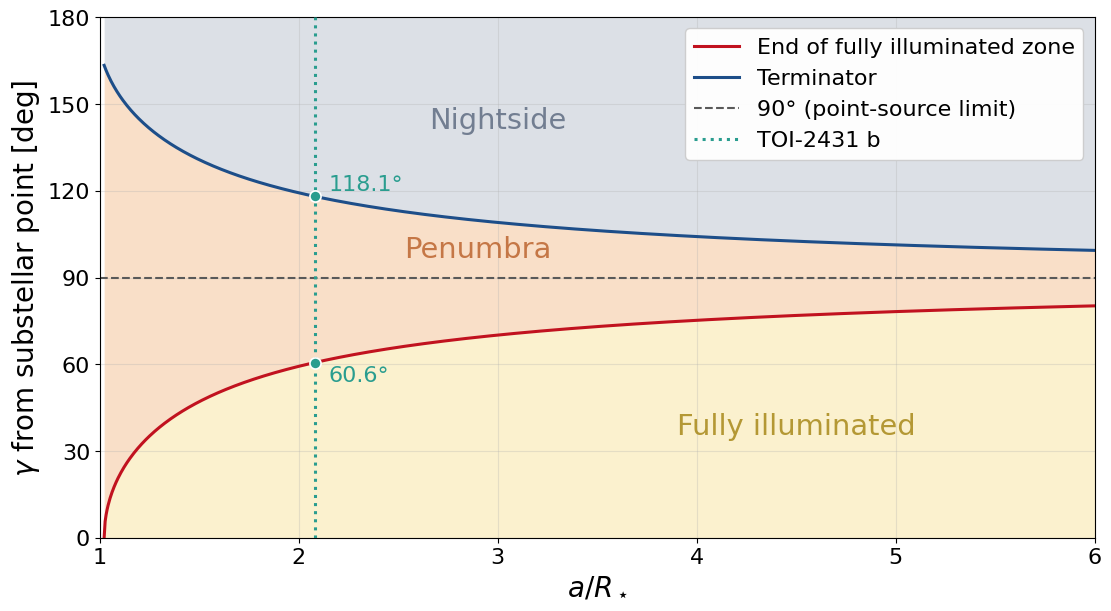

In [11]:
PAPER_MODE = True
# Illumination zones along a/Rs at the planet's own Rp/Rs, from PlanetParams' definitions (array-valued R, r2 = 1): the end of the fully illuminated zone,
# gamma_f = arccos((1 + Rp/Rs) / (a/Rs)), and the terminator, gamma_t = arccos(-(1 - Rp/Rs) / (a/Rs)); both tend to the plane-parallel 90 deg as a/Rs grows. The planet's own a/Rs is marked.
rp_rs, a_rs_planet = planet.r1 / planet.r2, planet.R / planet.r2
ars = np.linspace(1. + rp_rs, 6., 1000)
sweep = replace(planet, r1=rp_rs, r2=1., R=ars)
gamma_f, gamma_t = sweep.terminator_penumbra(unit="deg"), sweep.terminator_nightside(unit="deg")
gamma_f_p, gamma_t_p = planet.terminator_penumbra(unit="deg"), planet.terminator_nightside(unit="deg")

fig, ax = plt.subplots(figsize=(11, 6))
c_fi, c_pen, c_night, c_planet = "#f4d35e", "#ee964b", "#8d99ae", "#2a9d8f"
ax.fill_between(ars, 0., gamma_f, color=c_fi, alpha=0.3, lw=0, zorder=0)
ax.fill_between(ars, gamma_f, gamma_t, color=c_pen, alpha=0.3, lw=0, zorder=0)
ax.fill_between(ars, gamma_t, 180., color=c_night, alpha=0.3, lw=0, zorder=0)
ax.plot(ars, gamma_f, color="#c1121f", lw=2.2, label="End of fully illuminated zone")
ax.plot(ars, gamma_t, color="#1d4e89", lw=2.2, label="Terminator")
ax.axhline(90., ls="--", color="0.35", lw=1.5, label="90° (point-source limit)")

#the planet: its a/Rs, and its two angles read off the curves
ax.axvline(a_rs_planet, color=c_planet, ls=":", lw=2.2, zorder=3, label=planet.name)
ax.plot([a_rs_planet] * 2, [gamma_f_p, gamma_t_p], "o", color=c_planet, ms=8, mec="white", mew=1.2, zorder=6)
for gam, dy in ((gamma_f_p, -1), (gamma_t_p, 1)):
    ax.annotate(f"{gam:.1f}°", (a_rs_planet, gam), xytext=(10, 9 * dy), textcoords="offset points", ha="left", va="center", fontsize=10, color=c_planet, zorder=6)

# zone labels: plain, muted text in the tone of each band (nightside left of the legend; penumbra above the 90° line, where the band is wide)
label_kw = dict(ha="center", va="center", fontsize=13, alpha=0.75, zorder=5)
ax.text(4.5, np.interp(4.5, ars, gamma_f) / 2., "Fully illuminated", color="#9c7a00", **label_kw)
ax.text(2.9, (90. + np.interp(2.9, ars, gamma_t)) / 2., "Penumbra", color="#b4541a", **label_kw)
ax.text(3., (np.interp(3., ars, gamma_t) + 180.) / 2., "Nightside", color="#4f5d75", **label_kw)

ax.set(xlim=(1., 6.), ylim=(0., 180.), xlabel=r"$a/R_\star$", ylabel=r"$\gamma$ from substellar point [deg]",
       title=rf"Illumination zones vs. $a/R_\star$  ({planet.name}, $R_p/R_\star$ = {rp_rs:.4f})")
ax.set_yticks(np.arange(0, 181, 30)); ax.set_xticks(np.arange(1, 7))
ax.legend(loc="upper right", fontsize=10, framealpha=0.95)
ax.grid(alpha=0.3)
paper_figure(f"hi_zones", PAPER_MODE, fig=fig, label_size=20)   # axis labels stand out from the 16 pt tick labels
plt.show()

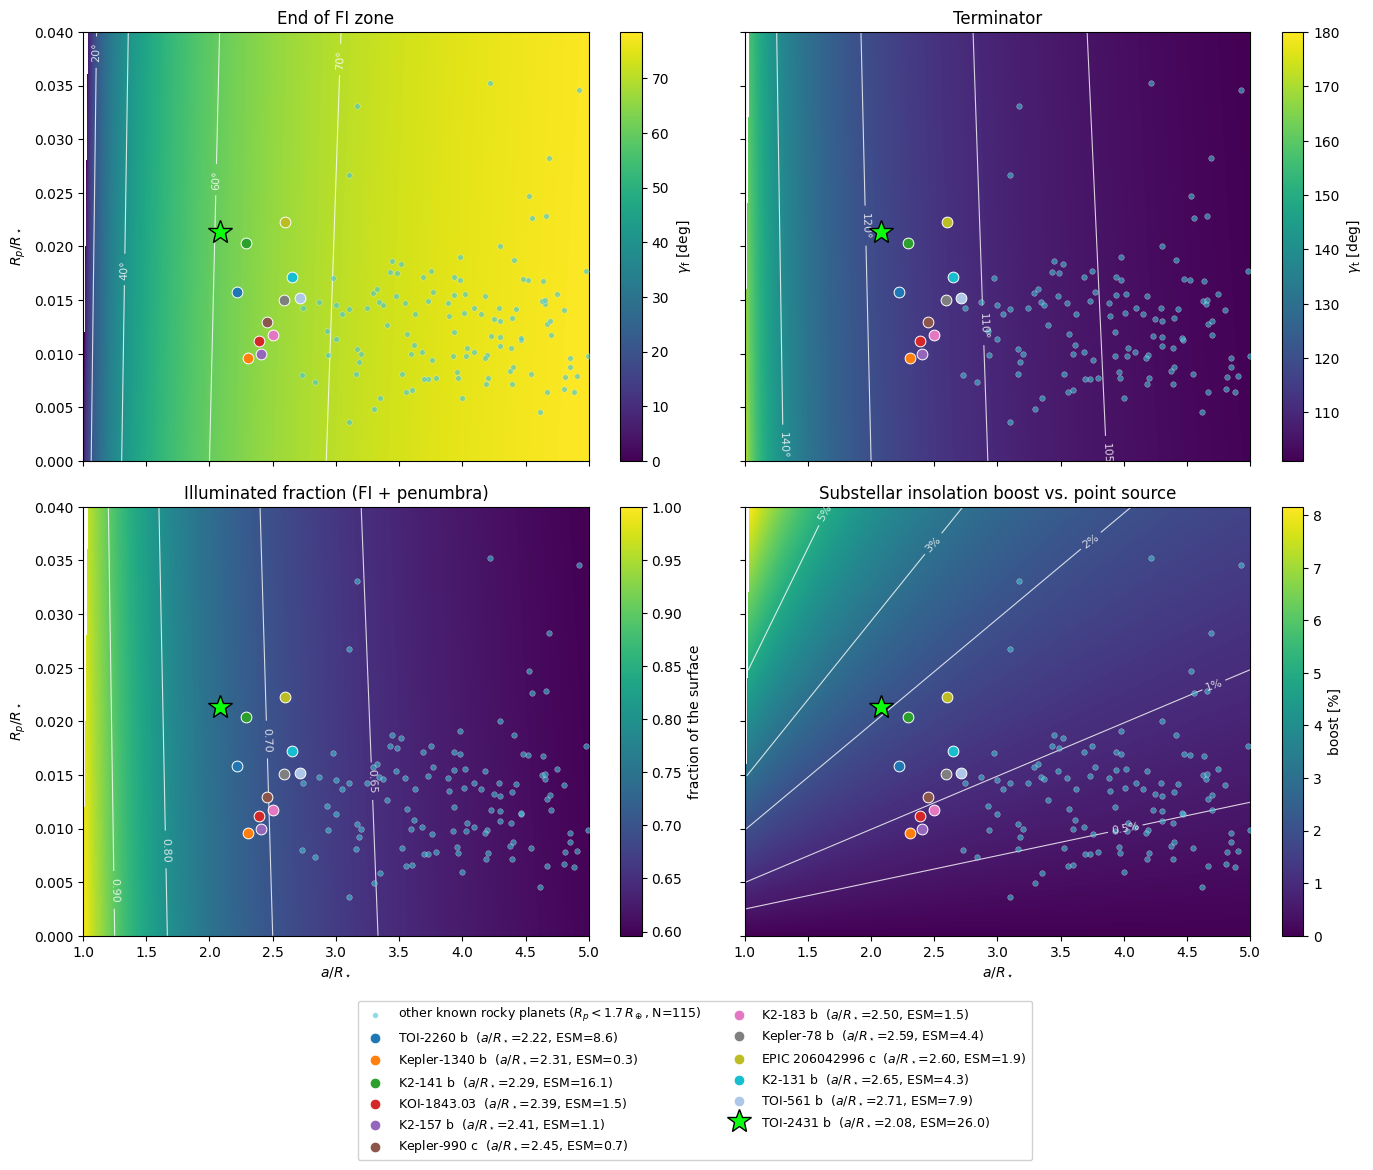

In [12]:
PAPER_MODE = False
rprs_grid = np.linspace(0., 0.04, 1000)   # r1/r2
ars_grid = np.linspace(1., 5., 1000)    # R/r2
RPRS, ARS = np.meshgrid(rprs_grid, ars_grid, indexing="ij")
valid = ARS >= 1. + RPRS                  # otherwise the planet overlaps the star

# The whole grid as ONE PlanetParams with array-valued r1, R (r2 = 1): the class methods are elementwise, so the maps use exactly the same definitions as for a single planet
grid_planet = replace(planet, r1=RPRS, r2=1., R=ARS)
with np.errstate(invalid="ignore", divide="ignore"):
    maps = [
        (grid_planet.terminator_penumbra(unit="deg"),   "End of FI zone",                             r"$\gamma_{\rm f}$ [deg]",   [20, 40, 60, 70],     "%d°"),
        (grid_planet.terminator_nightside(unit="deg"),  "Terminator",                                 r"$\gamma_{\rm t}$ [deg]",   [105, 110, 120, 140], "%d°"),
        (grid_planet.fraction_illuminated(),            "Illuminated fraction (FI + penumbra)",       "fraction of the surface", [0.65, 0.7, 0.8, 0.9], "%.2f"),
        (100. * grid_planet.substellar_boost(),         "Substellar insolation boost vs. point source", "boost [%]",     [0.5, 1, 2, 3, 5],    "%g%%"),
    ]

fig, axs = plt.subplots(2, 2, figsize=(14, 10), sharex=True, sharey=True)
for ax, (z, title, clabel, levels, fmt) in zip(axs.flat, maps):
    z = np.where(valid, z, np.nan)
    im = ax.pcolormesh(ars_grid, rprs_grid, z, shading="auto", cmap="viridis")
    cs = ax.contour(ars_grid, rprs_grid, z, levels=levels, colors="w", linewidths=.8, alpha=.8)
    ax.clabel(cs, fmt=fmt, fontsize=8, inline_spacing=3)
    fig.colorbar(im, ax=ax, label=clabel)
    overlay_planets(AGG, ax, "pl_ratror", (rprs_grid[0], rprs_grid[-1]), a_rs_lim=(ars_grid[0], ars_grid[-1]), target=planet, planets=PAPER_PLANETS)
    ax.set_title(title)
    ax.set_xlim(ars_grid[0], ars_grid[-1]); ax.set_ylim(rprs_grid[0], rprs_grid[-1])
for ax in axs[1]: ax.set_xlabel(r"$a/R_\star$")
for ax in axs[:, 0]: ax.set_ylabel(r"$R_p/R_\star$")

# one shared legend: the 10 rocky planets with the smallest a/Rs are named, the rest are background dots
fig.legend(*axs[0, 0].get_legend_handles_labels(), loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=2, fontsize=9, framealpha=.9)
plt.tight_layout()
paper_figure("illum_zone_maps", PAPER_MODE, fig=fig)
plt.show()

### Convergence to Naive model
With growing a/Rs the star shrinks towards a point source, so the hyper-illuminated insolation profile should converge to the naive (plane-parallel) cosine profile. The naive curve is normalized to its own maximum; each hyperillumination curve is divided by the naive maximum at the same a/Rs, so its peak directly shows the substellar boost (1 + `substellar_boost`) and the penumbra extends past 90°. The normalized naive curve is the same for every a/Rs, so a single one suffices.

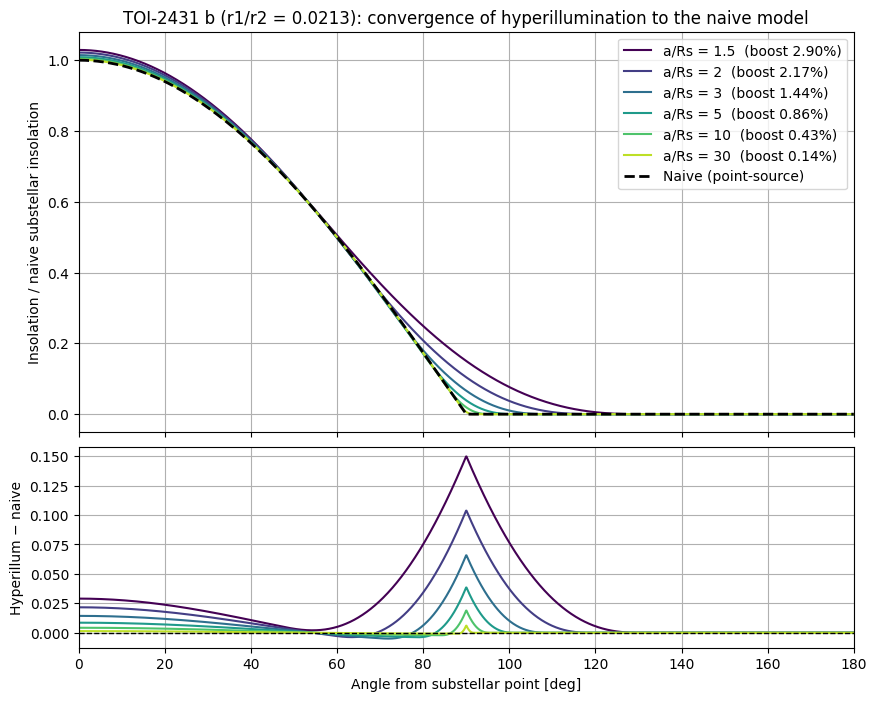

In [13]:
PAPER_MODE = False
ars_values = [1.5, 2, 3, 5, 10, 30]                 # R/r2 (planet's own value: planet.R/planet.r2)
gamma1_deg = np.linspace(0, 180, 2000)              # angle from substellar point [deg]
gamma1 = np.radians(gamma1_deg)

# Normalized naive profile (identical for all a/Rs: cos(gamma1) clipped at 90 deg)
insol_naive_norm = naive_insolation(gamma1, planet) / naive_insolation(gamma1, planet).max()

fig, (ax_top, ax_bot) = plt.subplots(2, 1, figsize=(10, 8), sharex=True, gridspec_kw=dict(height_ratios=[2, 1], hspace=0.05))
colors = plt.cm.viridis(np.linspace(0, 0.9, len(ars_values)))

for ars, color in zip(ars_values, colors):
    p = replace(planet, R=ars * planet.r2)          # keep r1, r2 of "planet", only change the orbital distance
    insol_hyper_norm = insolation_hyperillum(gamma1, p, u_B=u_B) / naive_insolation(gamma1, p).max()
    ax_top.plot(gamma1_deg, insol_hyper_norm, color=color, linewidth=1.5, label=f"a/Rs = {ars:g}  (boost {100*p.substellar_boost():.2f}%)")
    ax_bot.plot(gamma1_deg, insol_hyper_norm - insol_naive_norm, color=color, linewidth=1.5)

ax_top.plot(gamma1_deg, insol_naive_norm, color="black", linestyle="--", linewidth=2, label="Naive (point-source)")
ax_bot.axhline(0, color="black", linestyle="--", linewidth=1)

ax_top.set_ylabel("Insolation / naive substellar insolation")
ax_top.set_title(f"{planet.name} (r1/r2 = {planet.r1/planet.r2:.4f}): convergence of hyperillumination to the naive model")
ax_top.legend()
ax_top.grid()

ax_bot.set_xlabel("Angle from substellar point [deg]")
ax_bot.set_ylabel("Hyperillum − naive")
ax_bot.set_xlim(0, 180)
ax_bot.grid()
paper_figure(f"insol_convergence_ars_{planet.name.replace(' ', '')}", PAPER_MODE, fig=fig, tight=False)
plt.show()

### Planetary Insolation-/Heatmaps

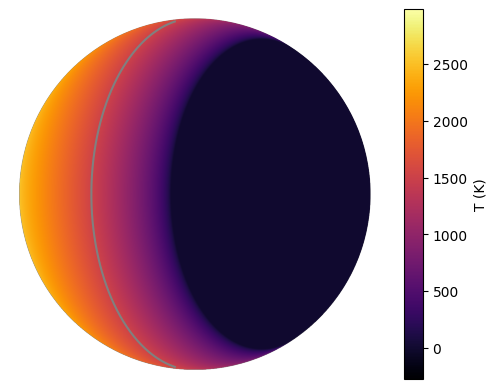

In [14]:
PAPER_MODE = False
phase = 0.35
ax=plot_insolmap(phase, planet, insolation_model="hyperillum", terminator=True, unit="temperature", u_B=u_B, A_B=A_B, theme=paper_theme(PAPER_MODE, "white"))
paper_figure(f"tempmap_hyperillum_{planet.name.replace(' ', '')}", PAPER_MODE, fig=ax)
plt.show()

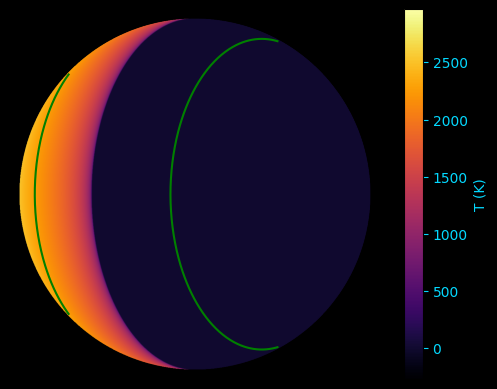

In [15]:
PAPER_MODE = False
phase = 0.35
ax=plot_insolmap(phase, planet, insolation_model="naive", show_penumbra="both", unit="temperature", u_B=u_B, A_B=A_B, theme=paper_theme(PAPER_MODE))
paper_figure(f"tempmap_naive_{planet.name.replace(' ', '')}", PAPER_MODE, fig=ax)
plt.show()

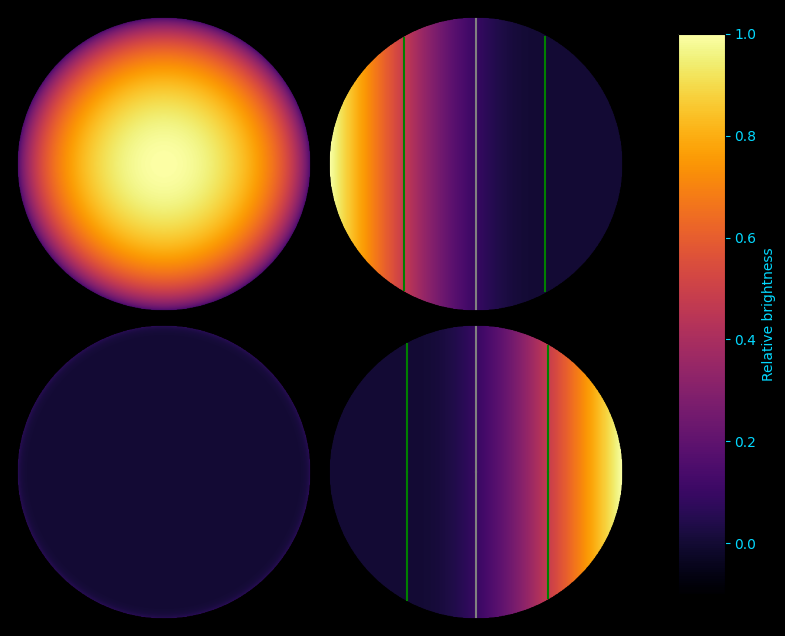

In [16]:
PAPER_MODE = False
ax=plot_quad_insolmap(planet, insolation_model="hyperillum", terminator=True, show_penumbra="both", unit="flux", u_B=u_B, A_B=A_B, theme=paper_theme(PAPER_MODE))
paper_figure(f"fluxmap_quad_hyperillum_{planet.name.replace(' ', '')}", PAPER_MODE, fig=ax)
plt.show()

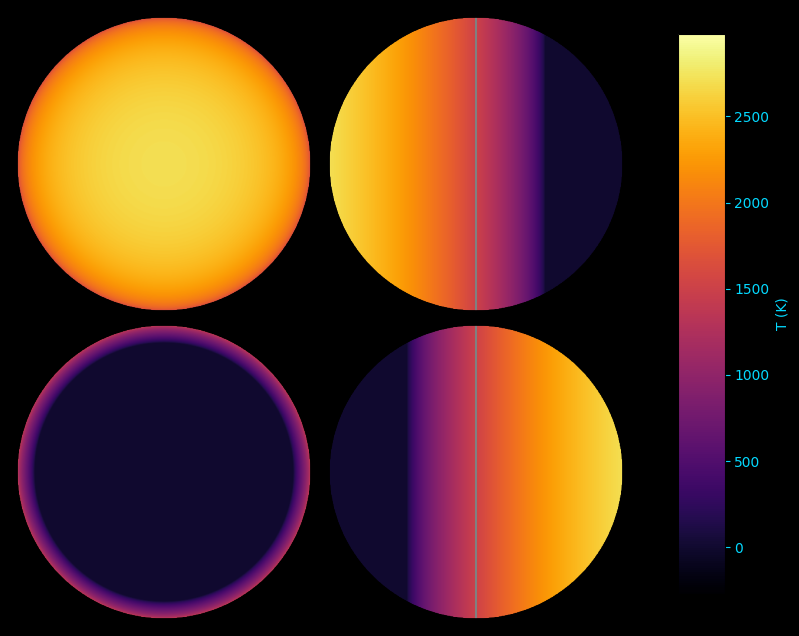

In [17]:
PAPER_MODE = False
ax=plot_quad_insolmap(planet, insolation_model="hyperillum", terminator=True, unit="temperature", u_B=u_B, A_B=A_B, theme=paper_theme(PAPER_MODE)) # , show_penumbra="both"
paper_figure(f"tempmap_quad_hyperillum_{planet.name.replace(' ', '')}", PAPER_MODE, fig=ax)
plt.show()

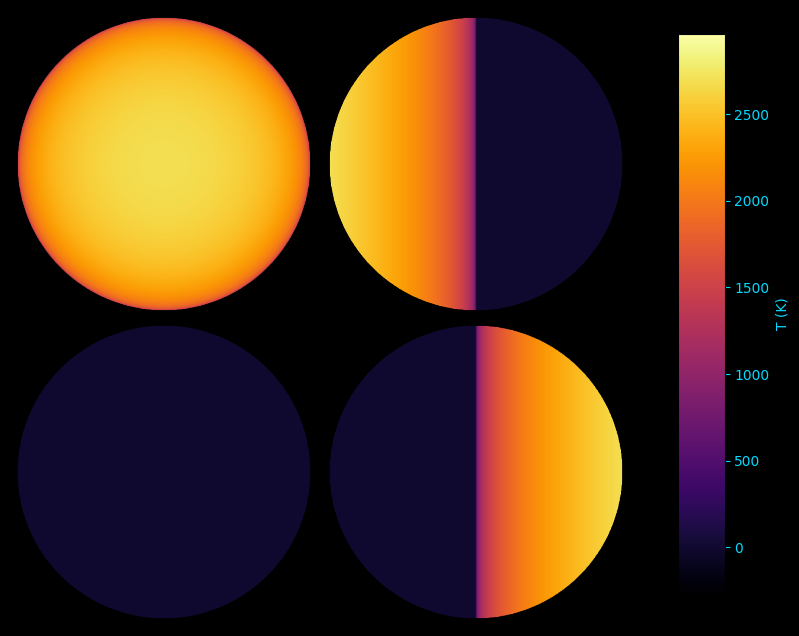

In [18]:
PAPER_MODE = False
ax=plot_quad_insolmap(planet, insolation_model="naive", unit="temperature", u_B=u_B, A_B=A_B, theme=paper_theme(PAPER_MODE))
paper_figure(f"tempmap_quad_naive_{planet.name.replace(' ', '')}", PAPER_MODE, fig=ax)
plt.show()

### Point source vs extended source at quadrature and on the nightside (shared colour bar)

The talk figure for slide 5: one 2 x 2 of temperature maps, rows = insolation model (point source / extended source), columns = viewing phase (quadrature / nightside), all four panels on one temperature scale so the panels are directly comparable. What to look for: the point-source nightside is at 0 K everywhere, the extended-source nightside shows the warm rim beyond the 90° line, and the daysides of the two quadrature views are nearly identical (the substellar boost is a few per cent). No terminator or penumbra lines, the maps speak for themselves. Saved at 200 dpi into the planet's plot folder.

Below it, the same grid on the same linear scale with a higher-contrast colour map (`hot` instead of inferno, set by `CONTRAST_CMAP`). Inferno's low end runs from black through dark purple, which hardly separates from the 0 K nightside; `hot` leaves black through red, so the thin warm ring of the extended-source nightside at transit stands out clearly while the point-source nightside stays black.

Both are drawn edge-on (inclination 90°, labelled in the corner of the top transit panel). The last grid shows the same contrast maps at the planet's real inclination (`planet.incl`, set by the `incl` argument of `plot_insolmap`), i.e. the transit as it is observed. The quadrature column does not change: the temperature map is symmetric about the star–planet axis, and at quadrature the line of sight is perpendicular to that axis at any inclination. At transit the sub-observer point moves 90° − i away from the antistellar point toward the pole that is tilted to the observer, so the warm ring becomes lopsided: wider at the top limb, where a thin crescent of the dayside comes into view, and squeezed into the bottom limb.

paper figure saved: paper_figures/quadmap_TOI2431b_boring.pdf


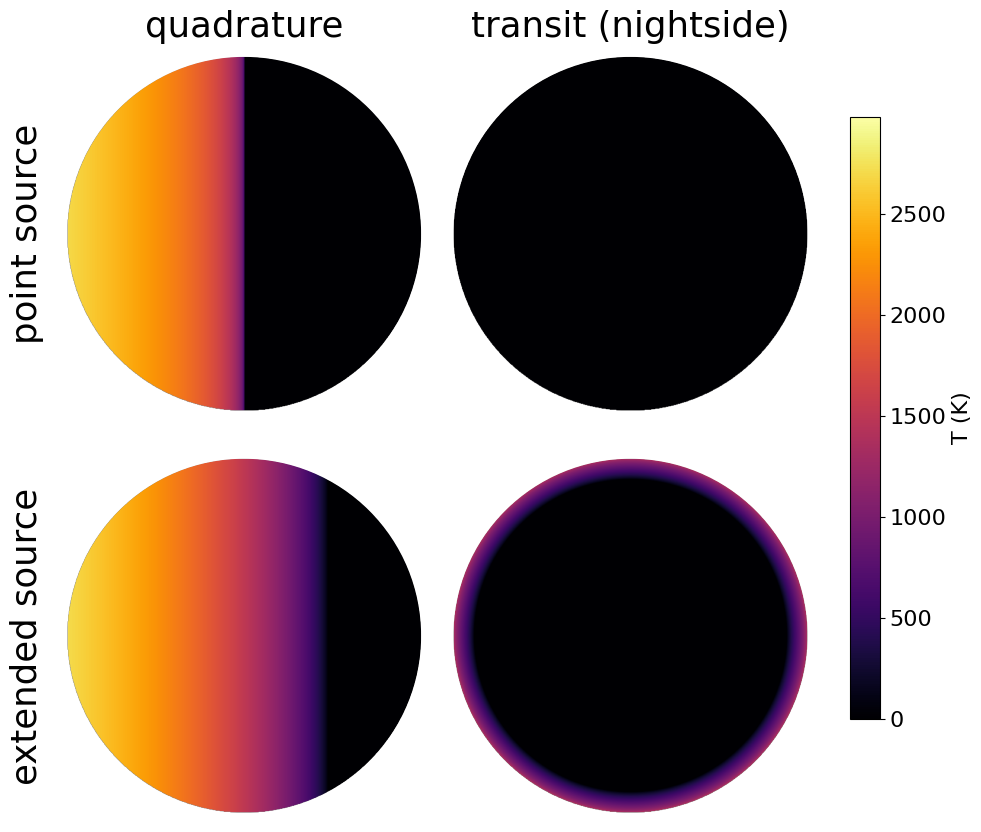

paper figure saved: paper_figures/quadmap_TOI2431b.pdf


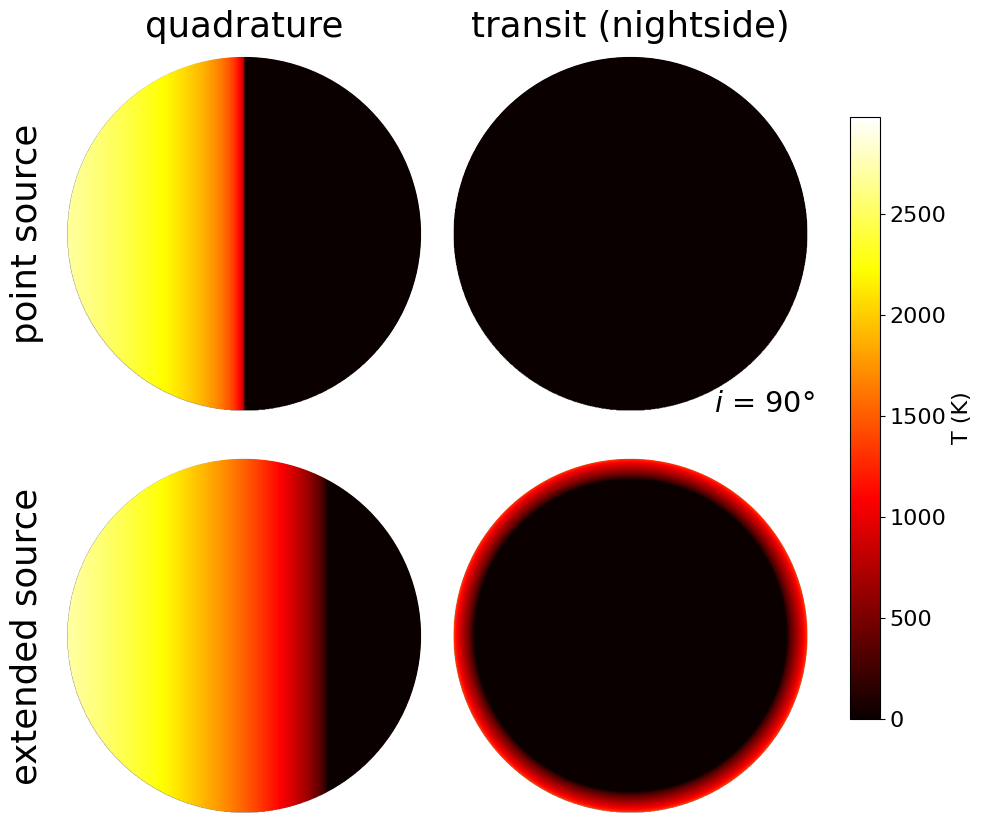

paper figure saved: paper_figures/quadmap_TOI2431b_incl74.pdf


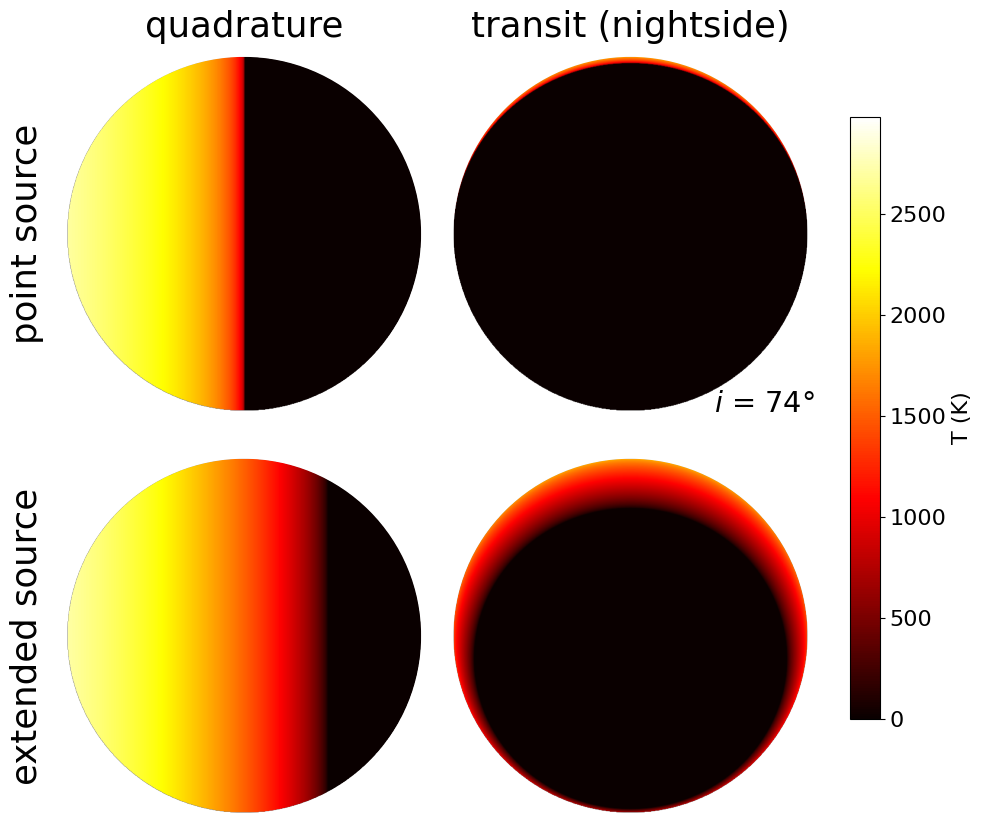

In [19]:
PAPER_MODE = True
# 2 x 2: rows = insolation models, columns = viewing phases; A_B of the setup cell; one temperature scale (0 to 1.1 x the hotter substellar temperature) for all four panels
models = [("naive", "point source"), ("hyperillum", "extended source")]
phases = [(0.25, "quadrature"), (0.5, "transit (nightside)")]
theme = paper_theme(PAPER_MODE, "white")   # "white" for a light slide, "black" for a dark one; always white in paper mode
bg, tc = ("black", "#04d9ff") if theme == "black" else ("white", "black")

T_hot = max(float(np.atleast_1d(surface_temperature(np.array([0.]), planet, m, u_B=u_B, A_B=A_B))[0]) for m, _ in models)
plots_dir = f"Plots {planet.name.replace(' ', '')}"   # e.g. "Plots TOI-2431b", the folder the animations live in
os.makedirs(plots_dir, exist_ok=True)

def model_phase_grid(cmap=None, incl=None):
    """The 2 x 2 grid of temperature maps on one shared, linear colour scale. cmap replaces plot_insolmap's inferno in every panel.
    incl [deg]: viewing inclination; None is the edge-on view (90°) without a label, a value is written into the corner of the top transit panel."""
    fig, axs = plt.subplots(len(models), len(phases), figsize=(2 * 4.3 / 0.865, 2 * 4.3), facecolor=bg)
    for i, (model, model_label) in enumerate(models):
        for j, (phase, phase_label) in enumerate(phases):
            plot_insolmap(phase, planet, u_B=u_B, A_B=A_B, min_temp=0., max_temp=1.1 * T_hot, n_grid=600, ax=axs[i, j], theme=theme, show_cax=False,
                          terminator=False, show_penumbra=None, insolation_model=model, unit="temperature", incl=90. if incl is None else incl)
            if cmap is not None: axs[i, j].images[0].set_cmap(cmap)
            if i == 0: axs[i, j].set_title(phase_label, color=tc, fontsize=16, pad=8)
        axs[i, 0].set_ylabel(model_label, color=tc, fontsize=16, labelpad=10)
        axs[i, 0].get_yaxis().set_visible(True); axs[i, 0].set_yticks([])   # the label only; plot_insolmap hides the axis
    if incl is not None: axs[0, -1].text(-1.04, -1.04, rf"$i$ = {incl:.0f}°", color=tc, fontsize=13, ha="right", va="bottom")   # x axis is reversed: -1 is the right edge
    fig.subplots_adjust(wspace=0.02, hspace=0.08, left=0.07, right=0.84, top=0.93, bottom=0.03)
    cbar = fig.colorbar(axs[0, 0].images[0], cax=fig.add_axes([0.87, 0.15, 0.03, 0.7]))
    cbar.ax.tick_params(colors=tc); cbar.set_label("T (K)", color=tc)
    return fig

fig = model_phase_grid()
fig.savefig(os.path.join(plots_dir, "tempmap_models_quadrature_nightside.png"), dpi=200, facecolor=bg)
paper_figure(f"quadmap_TOI2431b_boring", PAPER_MODE, fig=fig, tight=False)
plt.show()

# The same maps with a higher-contrast colour map (same linear scale): inferno's low end runs from black through dark purple, which hardly
# separates from the 0 K nightside; "hot" leaves black through red, so the warm rim of the extended-source nightside (the penumbra past 90°,
# seen at the limb in transit) stands out.
CONTRAST_CMAP = "hot"
fig = model_phase_grid(cmap=CONTRAST_CMAP, incl=90.)
fig.savefig(os.path.join(plots_dir, f"tempmap_models_quadrature_nightside_{CONTRAST_CMAP}.png"), dpi=200, facecolor=bg)
paper_figure(f"quadmap_TOI2431b", PAPER_MODE, fig=fig, tight=False)
plt.show()

# The same contrast maps seen at the planet's real inclination instead of edge-on. Quadrature is unchanged (the map is symmetric about the star-planet axis,
# which is perpendicular to the line of sight at quadrature for any inclination); at transit the sub-observer point is 90° - incl from the antistellar point.
fig = model_phase_grid(cmap=CONTRAST_CMAP, incl=planet.incl)
fig.savefig(os.path.join(plots_dir, f"tempmap_models_quadrature_nightside_{CONTRAST_CMAP}_incl{planet.incl:.0f}.png"), dpi=200, facecolor=bg)
paper_figure(f"quadmap_TOI2431b_incl{planet.incl:.0f}", PAPER_MODE, fig=fig, tight=False)
plt.show()


In [20]:
from IPython.display import Image

# animation_insolmap(planet, insolation_model="hyperillum", terminator=True, unit="temperature", A_B=A_B, theme=paper_theme(PAPER_MODE), filename="tempmap_hyperillum")
# animation_insolmap(planet, insolation_model="naive", terminator=False, unit="temperature", A_B=A_B, theme=paper_theme(PAPER_MODE), filename="tempmap_naive")
# animation_insolmap(planet, insolation_model="hyperillum", terminator=True, unit="flux", A_B=A_B, theme=paper_theme(PAPER_MODE), filename="fluxmap_hyperillum")
# animation_insolmap(planet, insolation_model="naive", terminator=False, unit="flux", A_B=A_B, theme=paper_theme(PAPER_MODE), filename="fluxmap_naive")

In [21]:
#Image(filename="tempmap_hyperillum.gif")

In [22]:
#Image(filename="tempmap_naive.gif")

In [23]:
#Image(filename="fluxmap_hyperillum.gif")

In [24]:
#Image(filename="fluxmap_naive.gif")